# Solving an MIS problem with QUBO Solver

The goal of the tutorial is to show how to solve a **Maximum Independent Set (MIS) problem using QUBO Solver**.

We use the functional API of `qubo-solver` throughout: rather than going through `Solver`/`SolverConfig`, we call each step of the pipeline directly. It is slightly more verbose, but gives better insight and control over each step — see [QUBO Solver in full](02-qubosolver-in-full.ipynb) for an introduction.

## Why use the QUBO Solver to resolve an MIS problem? 

MIS maps cleanly to QUBO. The MIS problem can be reformulated as a Quadratic Unconstrained Binary Optimization (QUBO) problem: assign a binary variable to each node, maximize the number of selected nodes, and penalize any pair of connected nodes that are both selected. This yields a QUBO matrix that the library consumes directly.

## Mapping MIS to QUBO

Each node $i$ in the graph is assigned a binary variable $x_i \in \{0, 1\}$, where **$x_i = 1$ means node $i$ is selected** as part of the independent set.

The MIS problem is then written as the following QUBO minimization:

$$\min_x \; -\sum_i x_i + P \sum_{(i,j) \in E} x_i x_j$$

The objective has two competing terms:

- **$-\sum_i x_i$** — minimizing this encourages selecting *as many nodes as possible*, since each selected node decreases the objective.
- **$P \sum_{(i,j) \in E} x_i x_j$** — for every edge $(i,j)$, if *both* endpoints are selected ($x_i = 1$ and $x_j = 1$), this term adds a penalty $P$ to the objective, discouraging invalid selections.

$P$ is a penalty parameter that must be large enough to ensure that no two adjacent nodes are ever both selected in the optimal solution. The choice of $P$ can influence the quality of the results — too small and the penalty may be insufficient to rule out invalid solutions, too large and it may distort the energy landscape. It is therefore worth tuning $P$ depending on the structure of the graph.

Once this mapping has be done, the solver finds the assignment of $x_i$ values that maximises the number of selected nodes while avoiding any pair of connected nodes — which is exactly the MIS problem.

## Practical example

### Step 1: Define your graph

For the sake of this tutorial, we will use a simple `networkx` **Unit Disk Graph with 6 nodes** as input, as it is easy to understand and visualize. 

Nodes : [0, 1, 2, 3, 4, 5]
Edges : [(0, 1), (0, 2), (1, 3), (2, 3), (3, 4), (3, 5)]


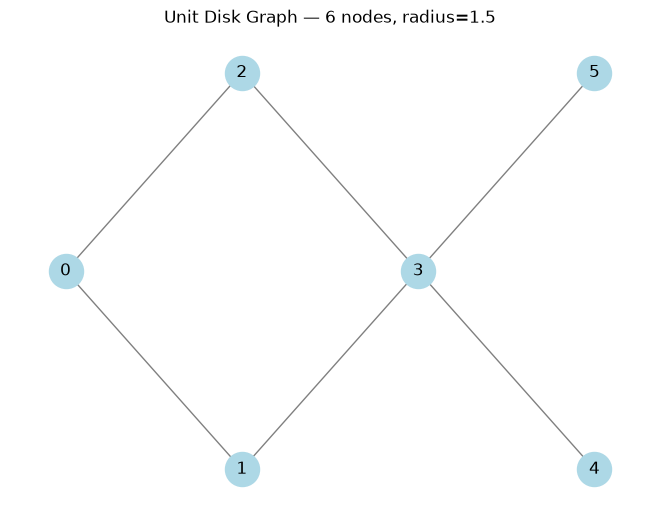

In [ ]:
from __future__ import annotations

from itertools import combinations
from math import dist

import matplotlib.pyplot as plt
import networkx as nx

# Node positions in 2D space
pos = {
    0: (0.0, 1.0),
    1: (1.0, 0.0),
    2: (1.0, 2.0),
    3: (2.0, 1.0),
    4: (3.0, 0.0),
    5: (3.0, 2.0),
}

# Build Unit Disk Graph: connect nodes within distance threshold
radius = 1.5
G = nx.Graph()
G.add_nodes_from(pos)
G.add_edges_from((i, j) for i, j in combinations(pos, 2) if dist(pos[i], pos[j]) <= radius)

print(f"Nodes : {list(G.nodes())}")
print(f"Edges : {list(G.edges())}")

nx.draw(
    G,
    pos=pos,
    with_labels=True,
    node_color="lightblue",
    node_size=600,
    font_size=12,
    edge_color="gray",
)
plt.title(f"Unit Disk Graph — {len(pos)} nodes, radius={radius}")
plt.show()

### Step 2: Solve with the quantum approach

We call each pipeline step directly: embed the QUBO onto a register, build a drive schedule, compile a program, and run it on a backend. The steps below use the same defaults as `SolverConfig()` — BLaDE embedding, a local-energy-scale drive, and a local emulator.

In [ ]:
import qoolqit

from qubosolver import (
    Instance,
    LocalEmulator,
    Solution,
    analysis,
    drive_shaping,
    embedding,
    matrix,
    solving,
)
from qubosolver.utils._random import seed_context

# Build the MIS QUBO from the graph: -1 on the diagonal, P/2 for each edge.
# The cost x^T Q x counts each edge twice (Q_ij and Q_ji), so each edge adds P in total.
P = 2.0  # penalty, must be > 1 so that selecting both endpoints of an edge never pays off
Q = matrix.tensor([[-1.0 if i == j else P / 2 * G.has_edge(i, j) for j in G] for i in G])
instance = Instance(Q)

# Default device and backend.
device = qoolqit.AnalogDeviceWithDMM()
backend = LocalEmulator()

# Seed the random steps (embedding, sampling) so the results are reproducible.
with seed_context(588):
    # Embed the QUBO onto a register (default embedding: BLaDE).
    register = embedding.blade.embed_for_device(instance, device)

    # Build a drive schedule for that register (default drive shaping: local-energy-scale).
    drive = drive_shaping.local_energy_scale.build_drive(instance, register, device=device)

    # Compile and run the program.
    program = solving.analog_quantum_sampling.compile(register, drive, device)
    job = backend.run(program)

    # Interpret the results as a Solution.
    quantum_solution = Solution.from_results(job.results(), instance)

# Conversion to pandas dataframe
quantum_df = analysis.to_dataframe([quantum_solution])
print(quantum_df)

  labels bitstrings  costs  counts  probs
0      0     011011   -4.0     961  0.961
1      0     100011   -3.0      25  0.025
2      0     010011   -3.0       9  0.009
3      0     001011   -3.0       4  0.004
4      0     011010   -3.0       1  0.001


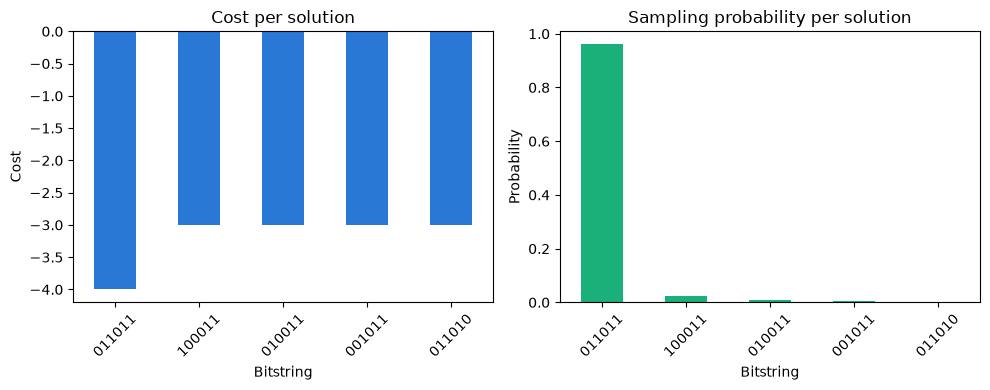

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

quantum_df.plot.bar(
    x="bitstrings",
    y="costs",
    ax=axes[0],
    color="#2a78d6",
    legend=False,
    rot=45,
    title="Cost per solution",
    xlabel="Bitstring",
    ylabel="Cost",
)
quantum_df.plot.bar(
    x="bitstrings",
    y="probs",
    ax=axes[1],
    color="#1baf7a",
    legend=False,
    rot=45,
    title="Sampling probability per solution",
    xlabel="Bitstring",
    ylabel="Probability",
)

fig.tight_layout()
plt.show()

### Step 3: Solve with the classical approach

To assess the quality of the quantum results, we compute the exact optimum with brute force, which evaluates every possible bitstring. This is only tractable for small instances like this one, but gives a reliable reference: the plot below shows how far each quantum sample is from the optimal cost.

In [ ]:
classical_solution = solving.brute_force.solve(instance)
classical_df = analysis.to_dataframe([classical_solution])
print(classical_df)

  labels bitstrings  costs  counts  probs
0      0     011011   -4.0       1    1.0


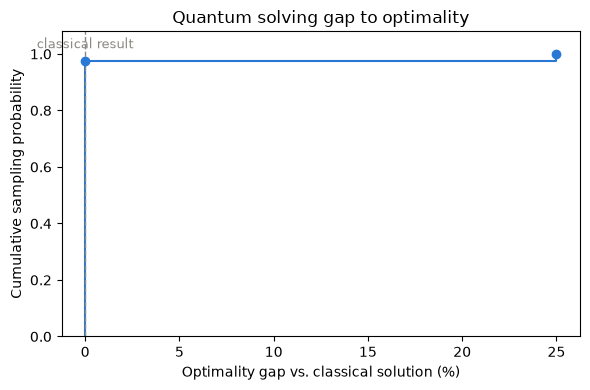

In [ ]:
import matplotlib.pyplot as plt

optimal_cost = classical_solution[0].cost

gaps = (100.0 * (quantum_solution.costs - optimal_cost) / abs(optimal_cost)).tolist()
probabilities = quantum_solution.probabilities

cumulative_probabilities = probabilities.cumsum(dim=0).tolist()

fig, ax = plt.subplots(figsize=(6, 4))
ax.step(
    [gaps[0], *gaps],
    [0.0, *cumulative_probabilities],
    where="post",
    color="#2a78d6",
)
ax.scatter(gaps, cumulative_probabilities, color="#2a78d6", zorder=3)
ax.axvline(0.0, color="#898781", linestyle="--", linewidth=1)
ax.text(0.0, 1.02, "classical result", color="#898781", ha="center", fontsize=9)

ax.set_title("Quantum solving gap to optimality")
ax.set_xlabel("Optimality gap vs. classical solution (%)")
ax.set_ylabel("Cumulative sampling probability")
ax.set_ylim(0, 1.08)
fig.tight_layout()
plt.show()

The functional API exposes each step the `Solver` performs internally — embedding, drive shaping, compiling, running, and interpreting results — as a separate call you can inspect, swap out, or run independently. See [QUBO Solver in full](02-qubosolver-in-full.ipynb) and the other tutorials for a closer look at each of these steps.